# ARC-09 Visualization Research & Implementation

**Project:** Quantum Space AGI - Space Mission Design Game  
**Workstream:** ARC-09 Visualization  
**Contributor:** Hridi  
**Reviewer:** Rafi  
**Status:** Independent visualization demonstration prepared for review; not an approved production integration.

## Purpose and scope

This notebook demonstrates reproducible synthetic dashboard and chart data preparation, validation, visualization, provenance notes, and UI-state design. It is independent of ARC-08 backend or model outputs. It is not a validated scientific model, NASA data analysis, mission simulation, or production API client.

All values are generated for demonstration and must not be interpreted as observations, mission results, physical thresholds, or research findings.

## 1. Environment and dependencies

The notebook checks the active Python and installed versions before importing required libraries. Required libraries are pandas, NumPy, and Matplotlib. No dependency is installed automatically. If a library is missing, use the environment owner's approved package setup and rerun. Version values are discovered at runtime; the notebook does not assert particular installed versions.

In [1]:
import sys
import importlib.util
import importlib.metadata as metadata

required_packages = ("pandas", "numpy", "matplotlib")
package_status = {}
for package in required_packages:
    installed = importlib.util.find_spec(package) is not None
    try:
        version = metadata.version(package) if installed else None
    except metadata.PackageNotFoundError:
        version = "installed; version metadata unavailable"
    package_status[package] = {"installed": installed, "version": version}

print("Python:", sys.version.split()[0])
print("Required package status:", package_status)
missing_packages = [name for name, info in package_status.items() if not info["installed"]]
if missing_packages:
    print("Visualization cells require these approved dependencies:", missing_packages)
else:
    print("Environment check complete; continue to imports.")

Python: 3.12.10
Required package status: {'pandas': {'installed': True, 'version': '3.1.1'}, 'numpy': {'installed': True, 'version': '2.5.4'}, 'matplotlib': {'installed': True, 'version': '3.11.2'}}
Environment check complete; continue to imports.


In [2]:
if missing_packages:
    raise RuntimeError("Required libraries are missing; no automatic installation was attempted.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 2.5.4
pandas: 3.1.1
Matplotlib: 3.11.2


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\HP\\AppData\\Local\\matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 2. Deterministic synthetic datasets

A fixed seed is recorded for reproducibility. Values are invented examples; their names and fields do not define approved product or scientific concepts. The displayed resource share is only a charting illustration, not resource capacity or consumption. Most examples use fixed illustrative values; scatter Y values are generated reproducibly from the fixed-seed random generator.

In [3]:
SEED = 20261109
rng = np.random.default_rng(SEED)

dashboard_metrics = pd.DataFrame([
    {"record_id": "metric-demo-01", "label": "Illustrative items", "value": 3, "unit": "synthetic items", "description": "Invented dashboard count for layout demonstration."},
    {"record_id": "metric-demo-02", "label": "Draft examples", "value": 1, "unit": "synthetic items", "description": "Invented dashboard count for layout demonstration."},
    {"record_id": "metric-demo-03", "label": "Review examples", "value": 2, "unit": "synthetic items", "description": "Invented dashboard count for layout demonstration."},
])
resource_demo = pd.DataFrame([
    {"record_id": "resource-demo-01", "label": "Example A", "share_pct": 68.0, "description": "Invented illustrative share; not a physical resource metric."},
    {"record_id": "resource-demo-02", "label": "Example B", "share_pct": 42.0, "description": "Invented illustrative share; not a physical resource metric."},
])
activity_demo = pd.DataFrame([
    {"record_id": f"activity-demo-{i:02d}", "label": f"Sample entry {i:02d}", "status": status, "description": "Invented activity text for layout demonstration."}
    for i, status in enumerate(("Planning", "In progress", "Reviewed"), start=1)
])
steps = np.arange(1, 6)
line_demo = pd.DataFrame({"record_id": [f"line-demo-{i:02d}" for i in steps], "step": steps, "sample_index": [4, 6, 5, 8, 9], "description": ["Synthetic unitless sample index for a demonstration step."] * len(steps)})
categories = ["A", "B", "C"]
grouped_demo = pd.DataFrame({"record_id": [f"bar-demo-{i}" for i in categories], "category": categories, "series_a": [5, 8, 6], "series_b": [7, 6, 9], "description": ["Synthetic placeholder category values; no domain meaning."] * len(categories)})
x_values = np.arange(1, 6)
scatter_demo = pd.DataFrame({"record_id": [f"scatter-demo-{i}" for i in x_values], "x": x_values, "y": rng.integers(1, 10, size=len(x_values)), "description": ["Synthetic unitless point coordinates."] * len(x_values)})

for frame in (dashboard_metrics, resource_demo, activity_demo, line_demo, grouped_demo, scatter_demo):
    frame["synthetic_label"] = "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS"

print("Fixed random seed:", SEED)
print("Synthetic tables: dashboard_metrics, resource_demo, activity_demo, line_demo, grouped_demo, scatter_demo")
print("Scatter Y values use the seeded random generator; the remaining demonstration values are specified directly.")

Fixed random seed: 20261109
Synthetic tables: dashboard_metrics, resource_demo, activity_demo, line_demo, grouped_demo, scatter_demo
Scatter Y values use the seeded random generator; the remaining demonstration values are specified directly.


## 3. Data validation

The reusable validator checks required columns, broad data types, missing values, duplicate identifiers, numeric finiteness, and empty input. It reports issues without dropping or repairing rows. These checks are a demonstration, not an approved domain schema or scientific-validity test.

In [4]:
def validate_dataset(frame, required_columns, expected_types=None, id_column=None, numeric_columns=None):
    """Return explicit validation findings without changing or dropping records."""
    expected_types = expected_types or {}
    numeric_columns = numeric_columns or []
    issues = []
    if not isinstance(frame, pd.DataFrame):
        return {"valid": False, "issues": ["Input is not a pandas DataFrame."]}
    if frame.empty:
        issues.append("Dataset is empty.")
    missing_columns = [column for column in required_columns if column not in frame.columns]
    if missing_columns:
        issues.append(f"Missing required columns: {missing_columns}")
    for column in required_columns:
        if column in frame.columns:
            missing_count = int(frame[column].isna().sum())
            if missing_count:
                issues.append(f"Column {column!r} contains {missing_count} missing value(s).")
    for column, expected in expected_types.items():
        if column not in frame.columns:
            continue
        series = frame[column]
        if expected == "numeric" and not pd.api.types.is_numeric_dtype(series):
            issues.append(f"Column {column!r} is not numeric.")
        elif expected == "string":
            non_null_values = series.dropna()
            invalid_string_count = int((~non_null_values.map(lambda value: isinstance(value, str))).sum())
            if invalid_string_count:
                issues.append(f"Column {column!r} contains {invalid_string_count} non-string non-missing value(s).")
    if id_column and id_column in frame.columns:
        duplicate_count = int(frame[id_column].duplicated(keep=False).sum())
        if duplicate_count:
            issues.append(f"Identifier column {id_column!r} has {duplicate_count} row(s) in duplicate groups.")
    for column in numeric_columns:
        if column not in frame.columns:
            continue
        converted = pd.to_numeric(frame[column], errors="coerce")
        invalid_count = int(converted.isna().sum())
        nonfinite_count = int((~np.isfinite(converted.dropna().to_numpy(dtype=float))).sum())
        if invalid_count:
            issues.append(f"Column {column!r} has {invalid_count} non-numeric or missing value(s).")
        if nonfinite_count:
            issues.append(f"Column {column!r} has {nonfinite_count} non-finite value(s).")
    return {"valid": not issues, "issues": issues or ["No issues found by these demonstration checks."]}

validation_specs = {
    "dashboard_metrics": (["record_id", "label", "value", "unit"], {"label": "string", "value": "numeric"}, "record_id", ["value"]),
    "resource_demo": (["record_id", "label", "share_pct"], {"label": "string", "share_pct": "numeric"}, "record_id", ["share_pct"]),
    "activity_demo": (["record_id", "label", "status"], {"label": "string", "status": "string"}, "record_id", []),
    "line_demo": (["record_id", "step", "sample_index"], {"step": "numeric", "sample_index": "numeric"}, "record_id", ["step", "sample_index"]),
    "grouped_demo": (["record_id", "category", "series_a", "series_b"], {"category": "string", "series_a": "numeric", "series_b": "numeric"}, "record_id", ["series_a", "series_b"]),
    "scatter_demo": (["record_id", "x", "y"], {"x": "numeric", "y": "numeric"}, "record_id", ["x", "y"]),
}
validation_results = {}
for name, (required, types, identifier, numeric) in validation_specs.items():
    validation_results[name] = validate_dataset(globals()[name], required, types, identifier, numeric)
pd.DataFrame([{"dataset": name, **result} for name, result in validation_results.items()])

,dataset,valid,issues
0,dashboard_metrics,True,[No issues found by these demonstration checks.]
1,resource_demo,True,[No issues found by these demonstration checks.]
2,activity_demo,True,[No issues found by these demonstration checks.]
3,line_demo,True,[No issues found by these demonstration checks.]
4,grouped_demo,True,[No issues found by these demonstration checks.]
5,scatter_demo,True,[No issues found by these demonstration checks.]


## 4. Invalid-data demonstrations

Small separate examples demonstrate missing values, duplicate identifiers, invalid or non-finite numeric values, and empty input. These fixtures are not part of the dashboard datasets.

In [5]:
missing_value_demo = pd.DataFrame({"record_id": ["m-1"], "value": [np.nan]})
duplicate_id_demo = pd.DataFrame({"record_id": ["d-1", "d-1"], "value": [1.0, 2.0]})
invalid_numeric_demo = pd.DataFrame({"record_id": ["n-1", "n-2"], "value": ["not-a-number", np.inf]})
empty_demo = pd.DataFrame(columns=["record_id", "value"])

invalid_demo_results = {
    "missing value": validate_dataset(missing_value_demo, ["record_id", "value"], {"value": "numeric"}, "record_id", ["value"]),
    "duplicate identifier": validate_dataset(duplicate_id_demo, ["record_id", "value"], {"value": "numeric"}, "record_id", ["value"]),
    "invalid numeric": validate_dataset(invalid_numeric_demo, ["record_id", "value"], {"value": "numeric"}, "record_id", ["value"]),
    "empty dataset": validate_dataset(empty_demo, ["record_id", "value"], {"value": "numeric"}, "record_id", ["value"]),
}
for name, result in invalid_demo_results.items():
    print(f"{name}: valid={result['valid']}; issues={result['issues']}")
print("No invalid row was dropped or repaired.")

missing value: valid=False; issues=["Column 'value' contains 1 missing value(s).", "Column 'value' has 1 non-numeric or missing value(s)."]
duplicate identifier: valid=False; issues=["Identifier column 'record_id' has 2 row(s) in duplicate groups."]
invalid numeric: valid=False; issues=["Column 'value' is not numeric.", "Column 'value' has 1 non-numeric or missing value(s).", "Column 'value' has 1 non-finite value(s)."]
empty dataset: valid=False; issues=['Dataset is empty.', "Column 'value' is not numeric."]
No invalid row was dropped or repaired.


## 5. Dashboard visualizations

Each Matplotlib chart has a synthetic-data notice. These are explanatory illustrations, not scientific results. Numeric axes are labeled unitless wherever no physical units are defined.

The source DataFrames below are the text/table alternatives for the plots. They are synthetic examples, not external observations.

In [6]:
for name, frame in (("dashboard metrics", dashboard_metrics), ("resource examples", resource_demo), ("activity examples", activity_demo), ("line data", line_demo), ("grouped-bar data", grouped_demo), ("scatter data", scatter_demo)):
    print(f"\n{name.upper()}")
    print(frame.to_string(index=False))


DASHBOARD METRICS
     record_id              label  value            unit                                        description                                          synthetic_label
metric-demo-01 Illustrative items      3 synthetic items Invented dashboard count for layout demonstration. SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS
metric-demo-02     Draft examples      1 synthetic items Invented dashboard count for layout demonstration. SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS
metric-demo-03    Review examples      2 synthetic items Invented dashboard count for layout demonstration. SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS

RESOURCE EXAMPLES
       record_id     label  share_pct                                                  description                                          synthetic_label
resource-demo-01 Example A       68.0 Invented illustrative share; not a physical resource metric. SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARC

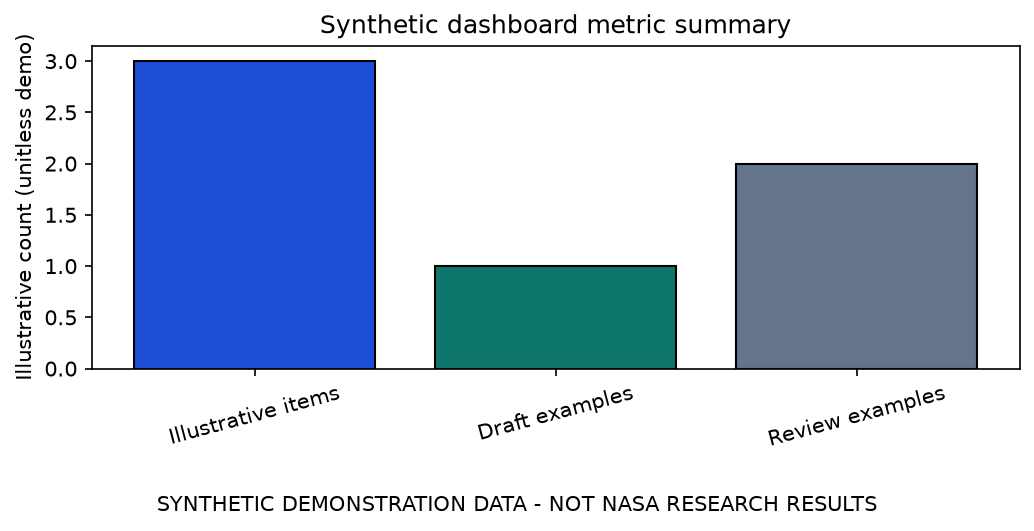

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dashboard_metrics["label"], dashboard_metrics["value"], color=["#1D4ED8", "#0F766E", "#64748B"], edgecolor="black")
ax.set_title("Synthetic dashboard metric summary")
ax.set_ylabel("Illustrative count (unitless demo)")
ax.tick_params(axis="x", rotation=15)
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

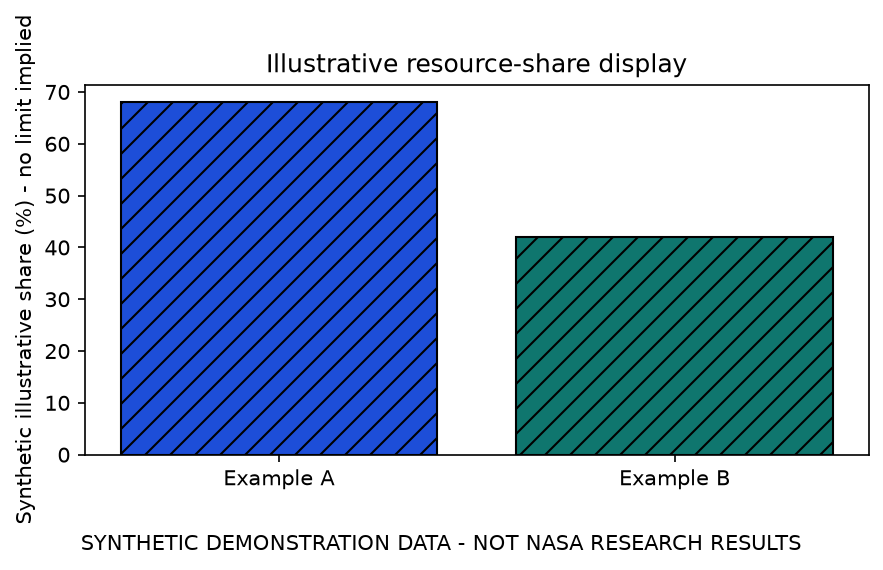

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(resource_demo["label"], resource_demo["share_pct"], color=["#1D4ED8", "#0F766E"], edgecolor="black", hatch="//")
ax.set_title("Illustrative resource-share display")
ax.set_ylabel("Synthetic illustrative share (%) - no limit implied")
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

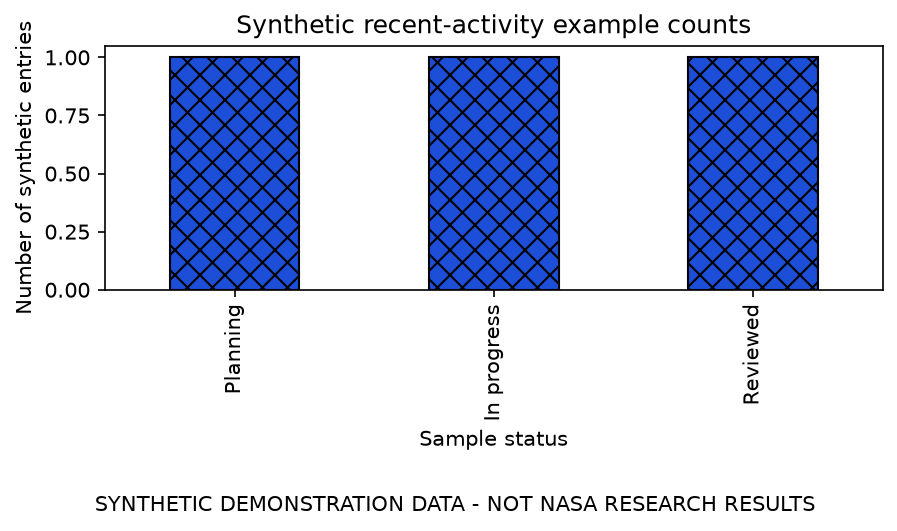

In [9]:
activity_counts = activity_demo.groupby("status", sort=False).size()
fig, ax = plt.subplots(figsize=(6, 3.5))
activity_counts.plot(kind="bar", ax=ax, color="#1D4ED8", edgecolor="black", hatch="xx")
ax.set_title("Synthetic recent-activity example counts")
ax.set_xlabel("Sample status")
ax.set_ylabel("Number of synthetic entries")
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

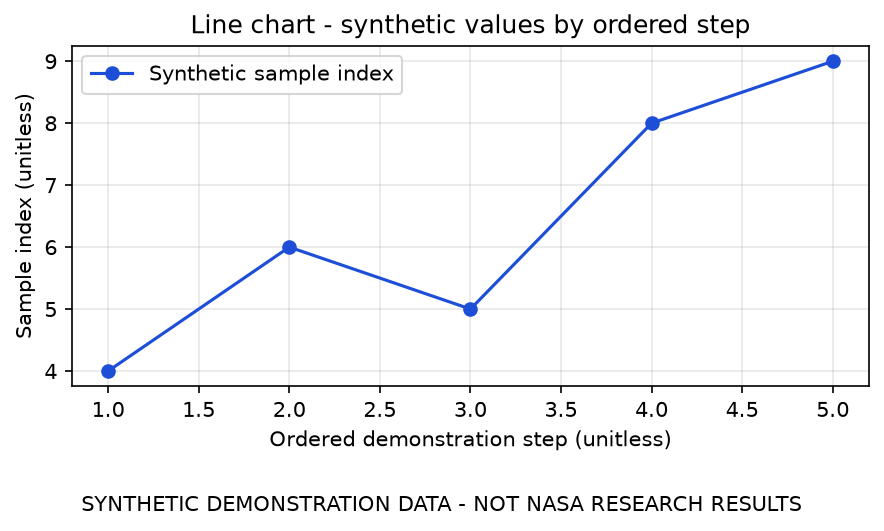

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(line_demo["step"], line_demo["sample_index"], marker="o", linestyle="-", color="#1D4ED8", label="Synthetic sample index")
ax.set_title("Line chart - synthetic values by ordered step")
ax.set_xlabel("Ordered demonstration step (unitless)")
ax.set_ylabel("Sample index (unitless)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

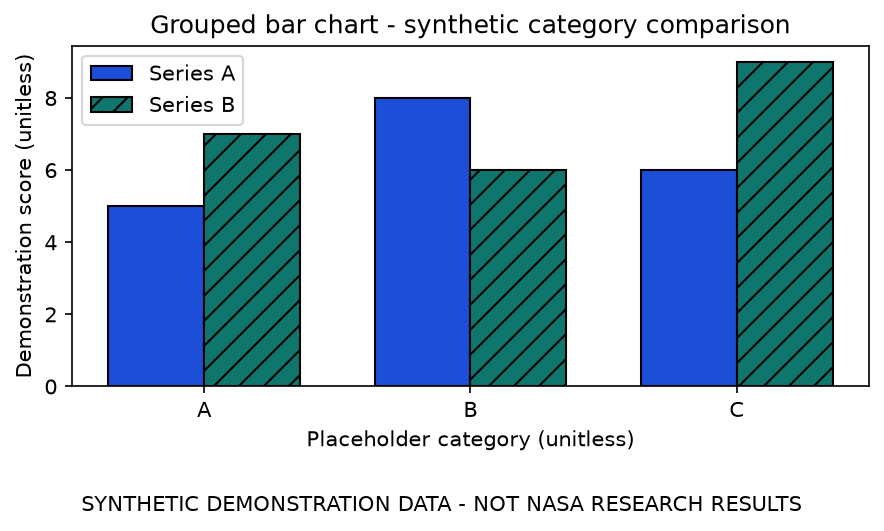

In [11]:
positions = np.arange(len(grouped_demo))
width = 0.36
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(positions - width / 2, grouped_demo["series_a"], width, label="Series A", color="#1D4ED8", edgecolor="black")
ax.bar(positions + width / 2, grouped_demo["series_b"], width, label="Series B", color="#0F766E", edgecolor="black", hatch="//")
ax.set_title("Grouped bar chart - synthetic category comparison")
ax.set_xlabel("Placeholder category (unitless)")
ax.set_ylabel("Demonstration score (unitless)")
ax.set_xticks(positions)
ax.set_xticklabels(grouped_demo["category"])
ax.legend()
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

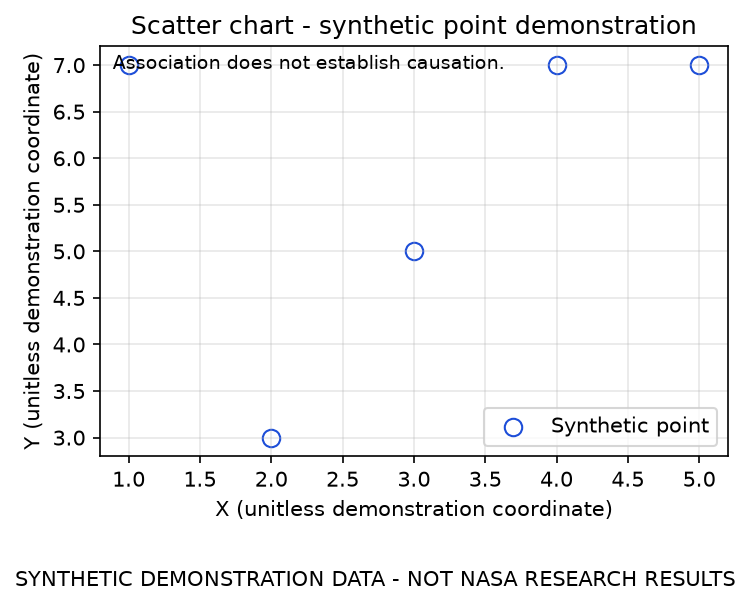

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(scatter_demo["x"], scatter_demo["y"], marker="o", facecolors="white", edgecolors="#1D4ED8", s=70, label="Synthetic point")
ax.set_title("Scatter chart - synthetic point demonstration")
ax.set_xlabel("X (unitless demonstration coordinate)")
ax.set_ylabel("Y (unitless demonstration coordinate)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.02, 0.98, "Association does not establish causation.", transform=ax.transAxes, va="top", fontsize=9)
fig.text(0.5, 0.01, "SYNTHETIC DEMONSTRATION DATA - NOT NASA RESEARCH RESULTS", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## 6. Data provenance and traceability

Every example carries a synthetic label. Metadata below records dataset identity, synthetic source, generation time, seed, field descriptions, transformation history, and validation status. The timestamp is the notebook execution time, not an observation time.

In [13]:
provenance = {
    "dataset_id": "arc09-synthetic-visualization-demo-v1",
    "dataset_id_scope": "Bundle-level ID for all six demonstration tables; table names identify each individual example.",
    "source_description": "Values specified inside this notebook solely for visualization demonstration; no external records used.",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": SEED,
    "field_definitions": {
        "record_id": "Stable identifier within this synthetic notebook example.",
        "label/category/status": "Display text for an illustrative UI example.",
        "value/share_pct/sample_index/series_a/series_b/x/y": "Synthetic numeric display value; physical meaning is not defined.",
        "unit": "Explicit demo label only; it does not imply a scientific unit."
    },
    "transformation_history": ["Created demonstration records", "Added synthetic-data disclosure labels", "Validated with notebook checks"],
    "validation_status": {name: result["valid"] for name, result in validation_results.items()},
}
provenance

{'dataset_id': 'arc09-synthetic-visualization-demo-v1', 'dataset_id_scope': 'Bundle-level ID for all six demonstration tables; table names identify each individual example.', 'source_description': 'Values specified inside this notebook solely for visualization demonstration; no external records used.', 'generated_at_utc': '2026-11-09T20:22:20.873298+00:00', 'random_seed': 20261109, 'field_definitions': {'record_id': 'Stable identifier within this synthetic notebook example.', 'label/category/status': 'Display text for an illustrative UI example.', 'value/share_pct/sample_index/series_a/series_b/x/y': 'Synthetic numeric display value; physical meaning is not defined.', 'unit': 'Explicit demo label only; it does not imply a scientific unit.'}, 'transformation_history': ['Created demonstration records', 'Added synthetic-data disclosure labels', 'Validated with notebook checks'], 'validation_status': {'dashboard_metrics': True, 'resource_demo': True, 'activity_demo': True, 'line_demo': Tru

### Future source-record traceability (not implemented)

Before production use, the approved data owner should define how source identifiers, retrieval/version timestamps, transformations, units, provenance categories, nullability, uncertainty, and model limitations travel with each value. This notebook proposes no API fields or contract. Unknown or absent values should remain visibly unknown rather than be converted into plausible-looking chart values.

## 7. Visualization states

The examples below are conceptual UI-state descriptions only. They make no network requests and do not represent API responses. Production implementations should connect these states to an approved request lifecycle and contract.

In [14]:
visualization_state_examples = {
    "loading": "Show labeled progress while an approved request is pending; do not present stale data as current without labeling it.",
    "empty": "Explain that a valid response contains no displayable records; provide next steps only if product-approved.",
    "invalid_data": "Report validation failure; do not silently omit or coerce invalid scientific values.",
    "error": "Show a clear failure message; offer retry only when supported by approved behavior.",
    "success": "Display validated values with approved labels, units, provenance, freshness, and supplied uncertainty metadata."
}
for state, description in visualization_state_examples.items():
    print(f"{state.upper()}: {description}")

LOADING: Show labeled progress while an approved request is pending; do not present stale data as current without labeling it.
EMPTY: Explain that a valid response contains no displayable records; provide next steps only if product-approved.
INVALID_DATA: Report validation failure; do not silently omit or coerce invalid scientific values.
ERROR: Show a clear failure message; offer retry only when supported by approved behavior.
SUCCESS: Display validated values with approved labels, units, provenance, freshness, and supplied uncertainty metadata.


## 8. Accessibility and scientific integrity

- Give each chart a meaningful title, labeled axes, and readable legends where multiple series appear.
- Do not rely on color alone: use distinct markers, hatching, labels, and legends where practical.
- Retain tabular data alternatives for charts used in a UI; notebook plots are accompanied by their source DataFrames.
- State units explicitly. Where no domain unit is defined, use an explicit unitless/demo label rather than infer one.
- Preserve synthetic versus real-data distinctions in chart labels and provenance.
- Do not invent uncertainty. If approved source data supplies uncertainty, retain its definition; otherwise state that it is unavailable.
- These examples support no scientific inference, causal claim, physical threshold, mission result, or model-performance claim.

## 9. Future integration architecture

Keep future responsibilities separate: (1) approved data acquisition, (2) contract/schema validation, (3) explicit transformations with traceability, (4) visualization, and (5) provenance presentation. This notebook implements only synthetic data creation, demonstration validation, and visualization.

Before integration, obtain approval for the production frontend repository/branch and stack, initial product scope, backend repository/service, API contract, authentication and environment configuration, error conventions, data semantics, units, provenance, and scientific limitations. No ARC-08 API, model, or backend component is connected here.

## 10. Limitations and conclusion

This notebook demonstrates deterministic synthetic data, simple structural validation, dashboard-style summaries, and three familiar chart forms. It does not demonstrate real NASA observations, scientific validity, mission operations, uncertainty propagation, API behavior, production accessibility conformance, or frontend integration.

Integration remains blocked until the production target and stack, approved initial visualization scope, authoritative data contracts, scientific semantics, and review approvals are available. Future work can map approved ARC-08 outputs only after their owner confirms product readiness and provenance.

## 11. References and reproducibility

### Documentation
- Python documentation: https://docs.python.org/3/
- NumPy documentation: https://numpy.org/doc/stable/
- pandas documentation: https://pandas.pydata.org/docs/
- Matplotlib documentation: https://matplotlib.org/stable/
- ARC-09 prototype README: `arc09-ui-prototype/README.md`
- ARC-09 prototype handoff: `arc09-ui-prototype/PROTOTYPE_HANDOFF.md`
- ARC-09 manual verification record: `docs/ARC09_MANUAL_VERIFICATION_REPORT.md`

### Reproduce
1. Use an approved Python 3 environment with pandas, NumPy, and Matplotlib installed.
2. Open this notebook in Jupyter and run cells from top to bottom.
3. Do not install packages from inside the notebook. Resolve missing dependencies through the environment owner's approved process.
4. The deterministic example seed is `20261109`. The recorded generation timestamp changes each run and is metadata, not scientific observation time.
5. This notebook was not executed in the preparation environment because a usable Python interpreter was unavailable; plots and runtime behavior therefore remain unverified.